# LinkedIn Analyst Skills — Streamlined Exploratory Analysis

**INFO 5006 — Assignment 1**

This notebook is intentionally short and focused on the two research questions.

## RQ1
**What skills are most commonly required in Business Analyst job advertisements?**

**Purpose:** identify candidate **core Business Analyst skills**.

## RQ2
**How do skill requirements differ between Business Analyst roles and other major analyst job families?**

**Purpose:** identify:
- shared skills;
- analyst families with the strongest Business Analyst skill overlap;
- additional skills that distinguish adjacent analyst pathways.

### Why DuckDB is used
DuckDB is used only to read/filter/join the large CSV files efficiently.  
After the relevant records are extracted, the actual analysis and visualisation use **Pandas + Matplotlib**.

`job_summary.csv` is not used because it is not required to answer RQ1 or RQ2.

In [1]:
# 1. SETUP + DOWNLOAD DATA

!pip -q install kagglehub duckdb

from pathlib import Path
from collections import OrderedDict
import re
import warnings

import kagglehub
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

path = kagglehub.dataset_download(
    "asaniczka/1-3m-linkedin-jobs-and-skills-2024"
)

data_dir = Path(path)
jobs_file = data_dir / "linkedin_job_postings.csv"
skills_file = data_dir / "job_skills.csv"

con = duckdb.connect()

con.execute(f'''
CREATE OR REPLACE VIEW jobs AS
SELECT *
FROM read_csv_auto(
    '{str(jobs_file).replace("'", "''")}',
    ALL_VARCHAR=TRUE,
    SAMPLE_SIZE=200000
)
''')

con.execute(f'''
CREATE OR REPLACE VIEW skills AS
SELECT *
FROM read_csv_auto(
    '{str(skills_file).replace("'", "''")}',
    ALL_VARCHAR=TRUE,
    SAMPLE_SIZE=200000
)
''')

job_count = con.execute("SELECT COUNT(*) FROM jobs").fetchone()[0]
skill_count = con.execute("SELECT COUNT(*) FROM skills").fetchone()[0]

print(f"Job postings: {job_count:,}")
print(f"Skill rows: {skill_count:,}")

100%|██████████| 1.88G/1.88G [00:19<00:00, 104MB/s]

Extracting files...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Job postings: 1,348,454
Skill rows: 1,296,381


## Section 1 — Compact data-quality check

### Purpose
Confirm that the two datasets used for the research questions are sufficiently complete and can be linked using `job_link`.

Only the quality measures that directly affect RQ1/RQ2 are retained.

In [2]:
# 2. DATA QUALITY SUMMARY

quality = con.execute('''
SELECT
    'Job Postings' AS dataset,
    COUNT(*) AS rows,
    COUNT(DISTINCT job_link) AS unique_job_links,
    SUM(CASE WHEN job_title IS NULL OR TRIM(job_title) = '' THEN 1 ELSE 0 END) AS missing_main_field
FROM jobs

UNION ALL

SELECT
    'Job Skills',
    COUNT(*),
    COUNT(DISTINCT job_link),
    SUM(CASE WHEN job_skills IS NULL OR TRIM(job_skills) = '' THEN 1 ELSE 0 END)
FROM skills
''').df()

quality["Missing %"] = (
    quality["missing_main_field"] / quality["rows"] * 100
).round(3)

display(quality)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,dataset,rows,unique_job_links,missing_main_field,Missing %
0,Job Postings,1348454,1348454,0.0,0.000
1,Job Skills,1296381,1296381,2007.0,0.155


## Section 2 — Define the Analyst population and job families

### Purpose
Identify jobs containing the word **Analyst**, then group relevant titles into interpretable job families for RQ2.

**Business Analyst is the reference group.**

Unmatched jobs remain `Other Analyst` so the classification can be checked rather than forced.

In [3]:
# 3. BROAD ANALYST POPULATION

analyst_jobs = con.execute('''
SELECT DISTINCT
    job_link,
    job_title
FROM jobs
WHERE LOWER(job_title) LIKE '%analyst%'
''').df()

analyst_jobs["title_clean"] = (
    analyst_jobs["job_title"]
    .fillna("")
    .str.strip()
    .str.lower()
)

# Keep Analyst / Analysts as a real word.
analyst_jobs = analyst_jobs[
    analyst_jobs["title_clean"].str.contains(
        r"\banalysts?\b",
        regex=True,
        na=False
    )
].copy()

print(f"Analyst jobs: {len(analyst_jobs):,}")
print(f"Unique Analyst titles: {analyst_jobs['title_clean'].nunique():,}")

Analyst jobs: 35,825
Unique Analyst titles: 18,514


,Jobs
analyst_family,
Other Analyst,16386
Business Analyst,4567
Finance Analyst,3995
Data Analyst,1943
Systems Analyst,1918
Program / Project Analyst,1317
Operations Analyst,901
Security Analyst,894
Intelligence Analyst,709


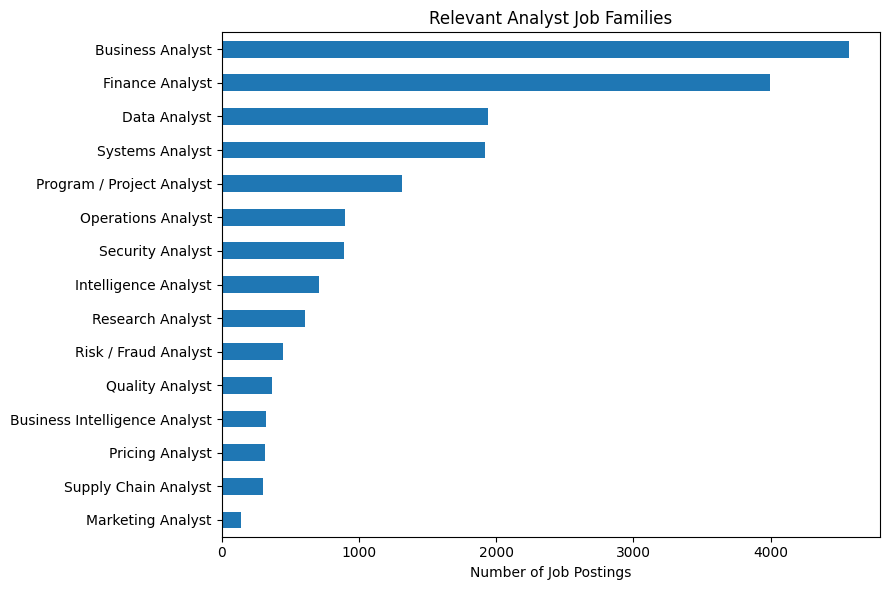

In [4]:
# 4. CLASSIFY ANALYST JOB FAMILIES

FAMILY_PATTERNS = OrderedDict({
    "Business Analyst": r"\bbusiness\s+analysts?\b",
    "Business Intelligence Analyst": r"\bbusiness\s+intelligence\s+analysts?\b|\bbi\s+analysts?\b",
    "Data Analyst": r"\bdata\s+analysts?\b|\banalytics\s+analysts?\b",
    "Finance Analyst": r"\bfinancial\s+analysts?\b|\bfinance\s+analysts?\b|\bfp&a\s+analysts?\b|\bbudget\s+analysts?\b|\btreasury\s+analysts?\b|\btax\s+analysts?\b",
    "Systems Analyst": r"\bsystems?\s+analysts?\b|\bbusiness\s+systems?\s+analysts?\b|\bcomputer\s+systems?\s+analysts?\b",
    "Security Analyst": r"\binformation\s+security\s+analysts?\b|\bcyber\s*security\s+analysts?\b|\bcybersecurity\s+analysts?\b|\bsecurity\s+analysts?\b",
    "Operations Analyst": r"\boperations?\s+analysts?\b|\boperational\s+analysts?\b",
    "Program / Project Analyst": r"\bprogram\s+analysts?\b|\bproject\s+analysts?\b",
    "Intelligence Analyst": r"\bintelligence\s+analysts?\b",
    "Research Analyst": r"\bresearch\s+analysts?\b",
    "Risk / Fraud Analyst": r"\brisk\s+analysts?\b|\bfraud\s+analysts?\b",
    "Quality Analyst": r"\bquality\s+analysts?\b|\bqa\s+analysts?\b",
    "Supply Chain Analyst": r"\bsupply\s+chain\s+analysts?\b|\blogistics\s+analysts?\b",
    "Pricing Analyst": r"\bpricing\s+analysts?\b",
    "Marketing Analyst": r"\bmarketing\s+analysts?\b|\bmarket\s+analysts?\b",
    "Behavior Analyst (Excluded)": r"\bbehavio[u]?r\s+analysts?\b"
})

def classify_family(title):
    for family, pattern in FAMILY_PATTERNS.items():
        if re.search(pattern, str(title), flags=re.IGNORECASE):
            return family
    return "Other Analyst"

analyst_jobs["analyst_family"] = (
    analyst_jobs["title_clean"].apply(classify_family)
)

family_counts = analyst_jobs["analyst_family"].value_counts()

display(family_counts.to_frame("Jobs"))

plot_counts = (
    family_counts
    .drop(["Other Analyst", "Behavior Analyst (Excluded)"], errors="ignore")
    .sort_values()
)

plt.figure(figsize=(9, 6))
plot_counts.plot(kind="barh")
plt.title("Relevant Analyst Job Families")
plt.xlabel("Number of Job Postings")
plt.ylabel("")
plt.tight_layout()
plt.show()

### Classification check

### Purpose
Inspect only the largest unclassified titles.

If an important and relevant analyst occupation appears here repeatedly, refine the job-family rules before finalising RQ2.

In [5]:
# 5. TOP UNCLASSIFIED TITLES + MAJOR FAMILY SELECTION

unclassified = (
    analyst_jobs.loc[
        analyst_jobs["analyst_family"] == "Other Analyst",
        "title_clean"
    ]
    .value_counts()
    .head(15)
)

display(unclassified.to_frame("Jobs"))

MIN_FAMILY_SIZE = 200

major_families = [
    family
    for family, count in family_counts.items()
    if (
        count >= MIN_FAMILY_SIZE
        and family not in {
            "Other Analyst",
            "Behavior Analyst (Excluded)"
        }
    )
]

major_families = (
    ["Business Analyst"] +
    [x for x in major_families if x != "Business Analyst"]
)

print("\nFamilies used for RQ2:")
for family in major_families:
    print(f"- {family}: {family_counts[family]:,}")

,Jobs
title_clean,
35g imagery analyst,73
senior analyst,73
payroll analyst,69
compensation analyst,62
inventory analyst,60
billing analyst,57
"senior analyst (bangkok-based, relocation provided)",56
procurement analyst,56
compliance analyst,56



Families used for RQ2:
- Business Analyst: 4,567
- Finance Analyst: 3,995
- Data Analyst: 1,943
- Systems Analyst: 1,918
- Program / Project Analyst: 1,317
- Operations Analyst: 901
- Security Analyst: 894
- Intelligence Analyst: 709
- Research Analyst: 608
- Risk / Fraud Analyst: 444
- Quality Analyst: 364
- Business Intelligence Analyst: 323
- Pricing Analyst: 316
- Supply Chain Analyst: 298


# Section 3 — RQ1: Top Business Analyst skills

### Purpose
Directly answer:

**What skills are most commonly required in Business Analyst job advertisements?**

### Measure
**Skill prevalence (%) = BA advertisements containing the skill / BA advertisements with usable skill data × 100**

Each skill is counted once per job.

In [6]:
# 6. GET BUSINESS ANALYST JOBS + SKILLS

ba_jobs = con.execute('''
SELECT DISTINCT job_link
FROM jobs
WHERE LOWER(job_title) LIKE '%business analyst%'
''').df()

con.register("ba_ids", ba_jobs)

ba_skills = con.execute('''
SELECT
    b.job_link,
    s.job_skills
FROM ba_ids b
LEFT JOIN skills s
    ON b.job_link = s.job_link
''').df()

ba_denominator = (
    ba_skills.loc[
        ba_skills["job_skills"].notna(),
        "job_link"
    ]
    .nunique()
)

skills_long = (
    ba_skills
    .dropna(subset=["job_skills"])
    .assign(skill=lambda x: x["job_skills"].str.split(","))
    .explode("skill")
)

skills_long["skill"] = (
    skills_long["skill"]
    .str.strip()
    .str.lower()
)

skills_long = (
    skills_long[
        skills_long["skill"].notna() &
        (skills_long["skill"] != "")
    ][["job_link", "skill"]]
    .drop_duplicates()
)

print(f"Business Analyst jobs: {ba_jobs['job_link'].nunique():,}")
print(f"BA jobs with skills: {ba_denominator:,}")
print(f"Skill coverage: {ba_denominator / ba_jobs['job_link'].nunique() * 100:.2f}%")

Business Analyst jobs: 4,576
BA jobs with skills: 4,440
Skill coverage: 97.03%


,Jobs,Prevalence %
Business Analysis,1943,43.76
Project Management,1507,33.94
Data Analysis,1452,32.70
Communication,1350,30.41
Sql,1044,23.51
Analytical Skills,902,20.32
Requirements Gathering,776,17.48
Problem Solving,763,17.18
Communication Skills,740,16.67
Teamwork,664,14.95


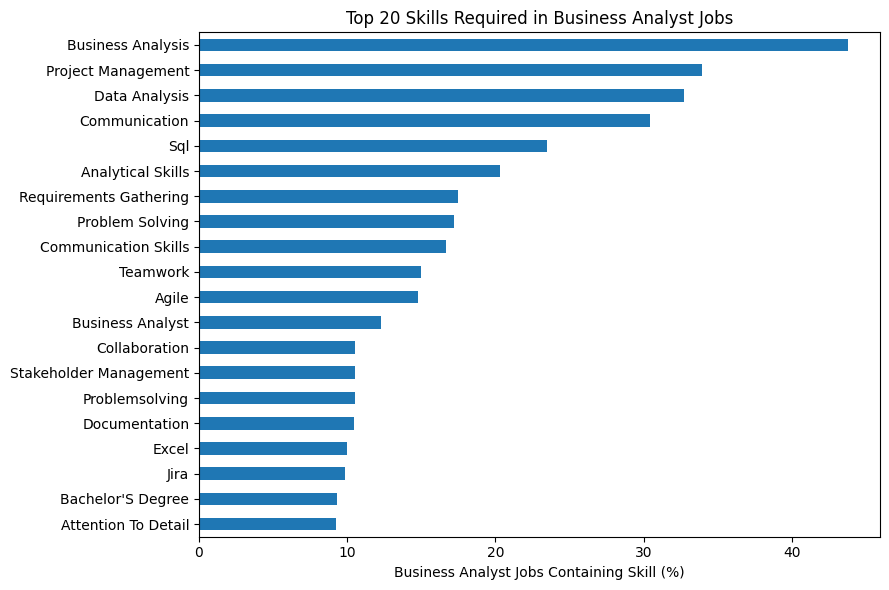

In [7]:
# 7. RQ1 RESULT — TOP 20 BA SKILLS

ba_skill_counts = (
    skills_long
    .groupby("skill")["job_link"]
    .nunique()
    .sort_values(ascending=False)
)

ba_top20 = pd.DataFrame({
    "Jobs": ba_skill_counts.head(20),
    "Prevalence %": (
        ba_skill_counts.head(20) /
        ba_denominator * 100
    ).round(2)
})

ba_top20.index = [x.title() for x in ba_top20.index]

display(ba_top20)

plt.figure(figsize=(9, 6))
ba_top20["Prevalence %"].sort_values().plot(kind="barh")
plt.title("Top 20 Skills Required in Business Analyst Jobs")
plt.xlabel("Business Analyst Jobs Containing Skill (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

# Section 4 — RQ2: Compare skills across Analyst families

### Purpose
Compare Business Analyst with the major analyst job families using **within-family percentages**.

The analysis keeps only three useful outputs:

1. skill-data coverage by family;
2. BA core-skill prevalence across families;
3. BA top-skill overlap and distinctive pathway skills.

In [8]:
# 8. JOIN MAJOR ANALYST FAMILIES TO SKILLS

comparison_jobs = (
    analyst_jobs[
        analyst_jobs["analyst_family"].isin(major_families)
    ][["job_link", "analyst_family"]]
    .drop_duplicates()
)

con.register("comparison_ids", comparison_jobs)

family_skill_strings = con.execute('''
SELECT
    c.job_link,
    c.analyst_family,
    s.job_skills
FROM comparison_ids c
LEFT JOIN skills s
    ON c.job_link = s.job_link
''').df()

family_coverage = (
    family_skill_strings
    .assign(has_skills=family_skill_strings["job_skills"].notna())
    .groupby("analyst_family")
    .agg(
        Jobs=("job_link", "nunique"),
        Jobs_with_skills=("has_skills", "sum")
    )
)

family_coverage["Skill coverage %"] = (
    family_coverage["Jobs_with_skills"] /
    family_coverage["Jobs"] * 100
).round(2)

display(family_coverage.sort_values("Jobs", ascending=False))

,Jobs,Jobs_with_skills,Skill coverage %
analyst_family,,,
Business Analyst,4567,4431,97.02
Finance Analyst,3995,3914,97.97
Data Analyst,1943,1900,97.79
Systems Analyst,1918,1881,98.07
Program / Project Analyst,1317,1180,89.60
Operations Analyst,901,838,93.01
Security Analyst,894,861,96.31
Intelligence Analyst,709,669,94.36
Research Analyst,608,557,91.61


In [9]:
# 9. CALCULATE SKILL PREVALENCE BY FAMILY

family_skills = (
    family_skill_strings
    .dropna(subset=["job_skills"])
    .assign(skill=lambda x: x["job_skills"].str.split(","))
    .explode("skill")
)

family_skills["skill"] = (
    family_skills["skill"]
    .str.strip()
    .str.lower()
)

family_skills = (
    family_skills[
        family_skills["skill"].notna() &
        (family_skills["skill"] != "")
    ][["job_link", "analyst_family", "skill"]]
    .drop_duplicates()
)

denominators = (
    family_skill_strings[
        family_skill_strings["job_skills"].notna()
    ]
    .groupby("analyst_family")["job_link"]
    .nunique()
)

family_prevalence = (
    family_skills
    .groupby(["analyst_family", "skill"])["job_link"]
    .nunique()
    .rename("Jobs")
    .reset_index()
)

family_prevalence["Prevalence %"] = (
    family_prevalence.apply(
        lambda r:
        r["Jobs"] / denominators[r["analyst_family"]] * 100,
        axis=1
    )
)

## RQ2 Visualisation 1 — BA core skills across job families

### Purpose
Take the **top 12 Business Analyst skills from RQ1** and show how common they are in the other analyst families.

This is the clearest visual answer to the first part of RQ2.

analyst_family,Business Analyst,Business Intelligence Analyst,Data Analyst,Finance Analyst,Intelligence Analyst,Operations Analyst,Pricing Analyst,Program / Project Analyst,Quality Analyst,Research Analyst,Risk / Fraud Analyst,Security Analyst,Supply Chain Analyst,Systems Analyst
skill,,,,,,,,,,,,,,
Business Analysis,43.8,4.5,7.2,2.5,0.4,4.8,3.2,1.8,2.2,1.8,1.6,0.0,0.4,14.2
Project Management,33.9,22.4,19.8,13.0,4.2,19.0,14.5,40.3,11.3,18.7,16.2,8.2,23.0,30.8
Data Analysis,32.7,57.4,69.2,32.8,25.0,35.0,45.0,24.5,25.7,50.6,27.4,6.6,41.6,20.4
Communication,30.4,33.0,28.2,27.4,9.1,24.8,31.5,20.3,17.4,20.5,25.3,9.9,28.8,23.7
Sql,23.5,62.5,61.0,9.5,1.5,15.6,24.1,1.4,17.1,8.6,22.1,4.8,6.6,22.2
Analytical Skills,20.4,19.9,18.6,20.9,7.2,18.0,27.0,9.4,12.2,12.7,16.7,8.0,12.0,16.3
Requirements Gathering,17.4,2.2,1.7,0.1,0.3,1.3,0.0,0.7,2.8,0.7,0.2,0.3,0.0,11.5
Problem Solving,17.2,26.0,16.5,16.9,6.0,16.1,17.7,17.0,11.3,11.8,12.1,7.7,25.2,16.0
Communication Skills,16.7,23.4,17.4,19.8,8.4,19.0,24.4,8.5,17.4,21.0,22.6,15.7,16.8,17.3


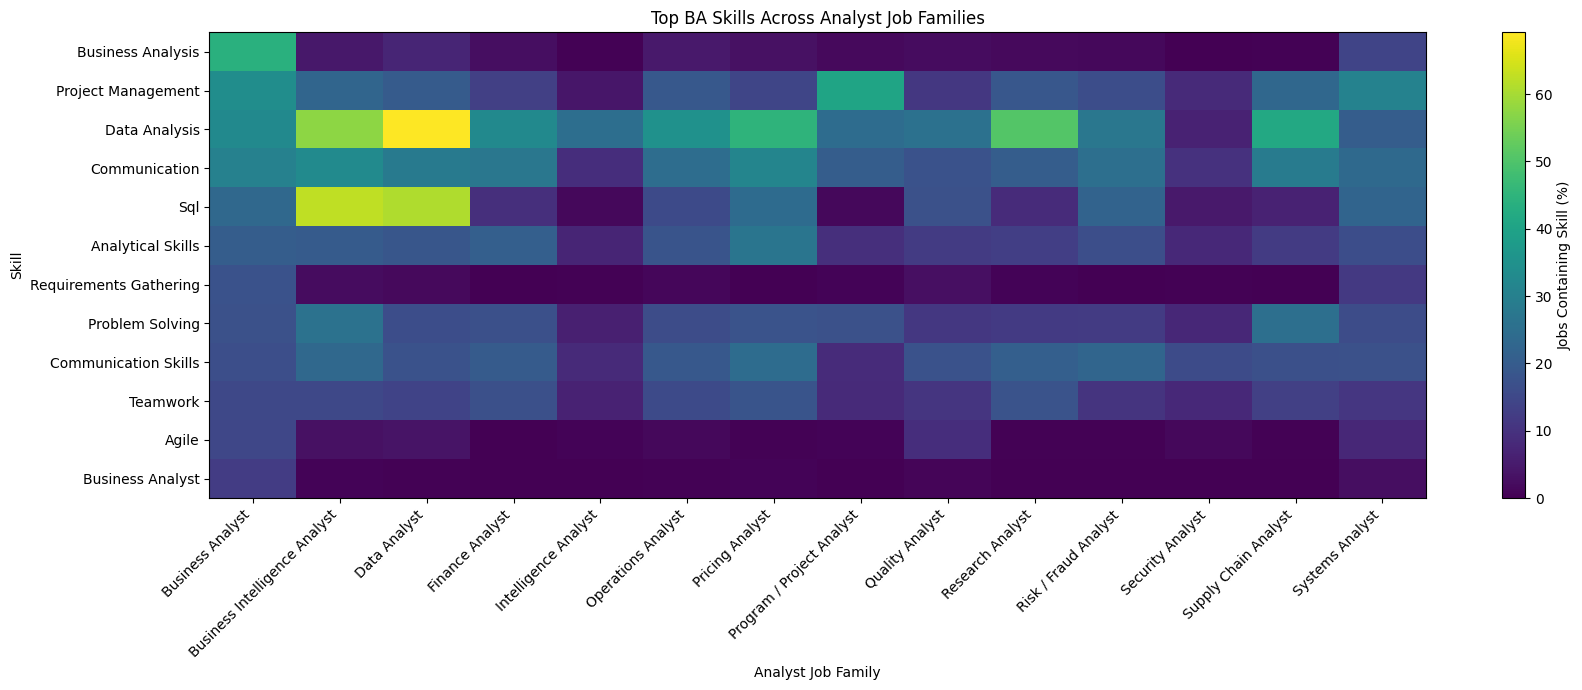

In [10]:
# 10. HEATMAP — TOP 12 BA SKILLS ACROSS FAMILIES

top_ba_keys = (
    ba_skill_counts
    .head(12)
    .index
    .tolist()
)

heatmap = (
    family_prevalence[
        family_prevalence["skill"].isin(top_ba_keys)
    ]
    .pivot(
        index="skill",
        columns="analyst_family",
        values="Prevalence %"
    )
    .fillna(0)
    .reindex(top_ba_keys)
)

cols = (
    ["Business Analyst"] +
    [c for c in heatmap.columns if c != "Business Analyst"]
)
heatmap = heatmap[cols]

display(heatmap.rename(index=lambda x: x.title()).round(1))

fig, ax = plt.subplots(figsize=(max(10, len(cols) * 1.25), 7))
img = ax.imshow(heatmap.values, aspect="auto")

ax.set_xticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(top_ba_keys)))
ax.set_yticklabels([x.title() for x in top_ba_keys])

ax.set_title("Top BA Skills Across Analyst Job Families")
ax.set_xlabel("Analyst Job Family")
ax.set_ylabel("Skill")

cbar = plt.colorbar(img, ax=ax)
cbar.set_label("Jobs Containing Skill (%)")

plt.tight_layout()
plt.show()

## RQ2 Visualisation 2 — Skill-profile overlap with Business Analyst

### Purpose
Compare the top 20 skills of each analyst family with the top 20 Business Analyst skills.

A higher percentage means the family shares more of the same high-demand skills with Business Analyst.

,Analyst Family,Shared Top-20 Skills,Overlap %
2,Systems Analyst,15,75.0
9,Quality Analyst,14,70.0
4,Operations Analyst,13,65.0
8,Risk / Fraud Analyst,12,60.0
11,Pricing Analyst,12,60.0
7,Research Analyst,12,60.0
12,Supply Chain Analyst,11,55.0
0,Finance Analyst,9,45.0
1,Data Analyst,8,40.0
10,Business Intelligence Analyst,8,40.0


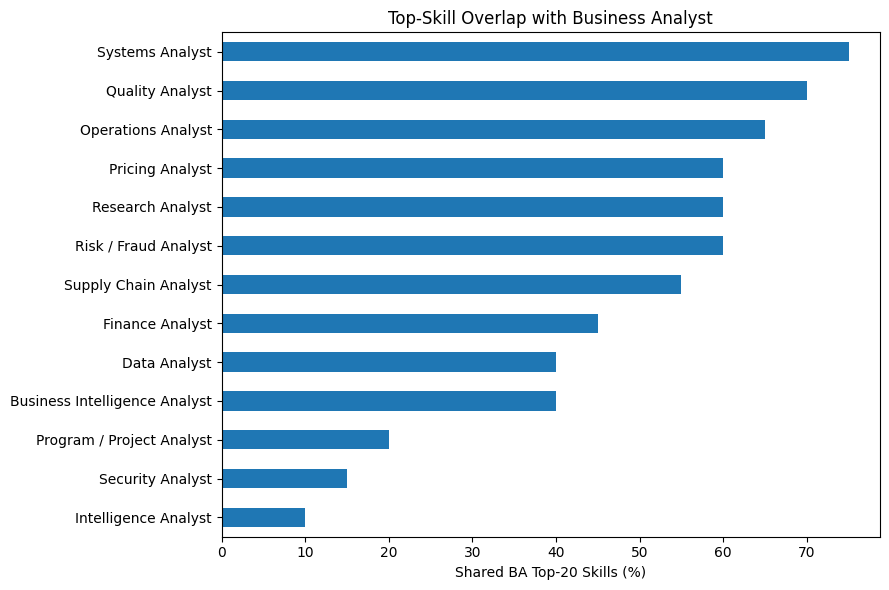

In [11]:
# 11. TOP-20 SKILL OVERLAP WITH BUSINESS ANALYST

TOP_N = 20
top_sets = {}

for family in major_families:
    top_sets[family] = set(
        family_prevalence[
            family_prevalence["analyst_family"] == family
        ]
        .sort_values("Prevalence %", ascending=False)
        .head(TOP_N)["skill"]
    )

ba_set = top_sets["Business Analyst"]

overlap_rows = []

for family in major_families:
    if family == "Business Analyst":
        continue

    shared = ba_set & top_sets[family]

    overlap_rows.append({
        "Analyst Family": family,
        "Shared Top-20 Skills": len(shared),
        "Overlap %": round(len(shared) / TOP_N * 100, 1)
    })

overlap = (
    pd.DataFrame(overlap_rows)
    .sort_values("Overlap %", ascending=False)
)

display(overlap)

plt.figure(figsize=(9, 6))
(
    overlap
    .set_index("Analyst Family")["Overlap %"]
    .sort_values()
    .plot(kind="barh")
)
plt.title("Top-Skill Overlap with Business Analyst")
plt.xlabel("Shared BA Top-20 Skills (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

## RQ2 Table — Distinctive pathway skills

### Purpose
Identify skills that are more common in another analyst family than in Business Analyst jobs.

**Difference = family prevalence − BA prevalence**

Only skills present in at least 5% of the family are considered.  
The table shows the **top 5** distinctive skills per family to keep the result concise.

In [12]:
# 12. TOP 5 DISTINCTIVE SKILLS PER FAMILY

wide = (
    family_prevalence
    .pivot(
        index="skill",
        columns="analyst_family",
        values="Prevalence %"
    )
    .fillna(0)
)

distinctive_results = []

for family in major_families:
    if family == "Business Analyst":
        continue

    temp = pd.DataFrame({
        "BA %": wide["Business Analyst"],
        "Family %": wide[family]
    })

    temp["Difference (pp)"] = temp["Family %"] - temp["BA %"]
    temp = temp[temp["Family %"] >= 5]

    top5 = (
        temp
        .sort_values("Difference (pp)", ascending=False)
        .head(5)
        .reset_index()
        .rename(columns={"skill": "Skill"})
    )

    top5["Analyst Family"] = family
    distinctive_results.append(top5)

distinctive = pd.concat(distinctive_results, ignore_index=True)

display(
    distinctive[
        ["Analyst Family", "Skill", "BA %", "Family %", "Difference (pp)"]
    ].round(2)
)

,Analyst Family,Skill,BA %,Family %,Difference (pp)
0,Finance Analyst,financial analysis,3.88,47.78,43.90
1,Finance Analyst,accounting,3.52,42.77,39.25
2,Finance Analyst,budgeting,3.00,37.53,34.53
3,Finance Analyst,forecasting,5.75,33.96,28.20
4,Finance Analyst,finance,6.32,32.29,25.98
...,...,...,...,...,...
60,Supply Chain Analyst,supply chain management,2.82,41.97,39.15
61,Supply Chain Analyst,logistics,0.70,31.75,31.05
62,Supply Chain Analyst,inventory management,3.50,29.20,25.70
63,Supply Chain Analyst,sap,3.68,20.07,16.39


# Section 5 — Results to send for the Final Analytic Plan

After running the notebook, send these outputs:

### RQ1
- Number of Business Analyst jobs
- BA skill coverage
- Top 20 BA skills + prevalence %

### RQ2
- Analyst family counts
- Top 15 unclassified titles
- Families selected for comparison
- Family skill-coverage table
- BA core-skill heatmap
- Skill-overlap ranking
- Distinctive-skill table

These results are enough to decide the final research questions and rewrite the Analytic Plan.

In [13]:
# 13. QUICK SUMMARY

print("=" * 70)
print("KEY RESULTS")
print("=" * 70)

print(f"\nAll jobs: {job_count:,}")
print(f"Analyst jobs: {len(analyst_jobs):,}")
print(f"Business Analyst jobs: {ba_jobs['job_link'].nunique():,}")
print(f"BA skill coverage: {ba_denominator / ba_jobs['job_link'].nunique() * 100:.2f}%")

print("\nFamilies used for RQ2:")
for family in major_families:
    print(f"- {family}: {family_counts[family]:,}")

print("\nTop 10 BA skills:")
for skill, row in ba_top20.head(10).iterrows():
    print(f"- {skill}: {row['Prevalence %']:.2f}%")

if len(overlap):
    best = overlap.iloc[0]
    print(
        f"\nHighest BA top-skill overlap: "
        f"{best['Analyst Family']} ({best['Overlap %']:.1f}%)"
    )

KEY RESULTS

All jobs: 1,348,454
Analyst jobs: 35,825
Business Analyst jobs: 4,576
BA skill coverage: 97.03%

Families used for RQ2:
- Business Analyst: 4,567
- Finance Analyst: 3,995
- Data Analyst: 1,943
- Systems Analyst: 1,918
- Program / Project Analyst: 1,317
- Operations Analyst: 901
- Security Analyst: 894
- Intelligence Analyst: 709
- Research Analyst: 608
- Risk / Fraud Analyst: 444
- Quality Analyst: 364
- Business Intelligence Analyst: 323
- Pricing Analyst: 316
- Supply Chain Analyst: 298

Top 10 BA skills:
- Business Analysis: 43.76%
- Project Management: 33.94%
- Data Analysis: 32.70%
- Communication: 30.41%
- Sql: 23.51%
- Analytical Skills: 20.32%
- Requirements Gathering: 17.48%
- Problem Solving: 17.18%
- Communication Skills: 16.67%
- Teamwork: 14.95%

Highest BA top-skill overlap: Systems Analyst (75.0%)
